In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv("Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

In [6]:
df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


In [7]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')

In [8]:
df.totalcharges = df.totalcharges.fillna(df.totalcharges.median())

In [9]:
df.churn.head()

0     no
1     no
2    yes
3     no
4    yes
Name: churn, dtype: str

In [10]:
df.churn = (df.churn == 'yes').astype(int)

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)

In [13]:
df_train , df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

In [14]:
len(df_test), len(df_val), len(df_train)

(1409, 1409, 4225)

In [15]:
df_train = df_train.reset_index(drop = True)
df_val = df_val.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

In [16]:
y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

In [17]:
del df_train['churn']
del df_val['churn']
del df_test['churn']

In [18]:
df_full_train = df_full_train.reset_index(drop = True)

In [19]:
df_full_train.churn.value_counts(normalize = True)

churn
0    0.730032
1    0.269968
Name: proportion, dtype: float64

In [20]:
global_churn_rate = df_full_train.churn.mean()
print(round(global_churn_rate, 2))

0.27


In [21]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

In [22]:
df_full_train.columns

Index(['customerid', 'gender', 'seniorcitizen', 'partner', 'dependents',
       'tenure', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod', 'monthlycharges', 'totalcharges', 'churn'],
      dtype='str')

In [23]:
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice',
       'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
       'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
       'paymentmethod']

In [24]:
df_full_train[categorical].nunique()

gender              2
seniorcitizen       2
partner             2
dependents          2
phoneservice        2
multiplelines       3
internetservice     3
onlinesecurity      3
onlinebackup        3
deviceprotection    3
techsupport         3
streamingtv         3
streamingmovies     3
contract            3
paperlessbilling    2
paymentmethod       4
dtype: int64

In [25]:
churn_female = df_full_train[df_full_train.gender == 'female'].churn.mean()
print(churn_female)

0.27682403433476394


In [26]:
churn_male = df_full_train[df_full_train.gender == 'male'].churn.mean()
print(churn_male)

0.2632135306553911


In [27]:
churn_partner = df_full_train[df_full_train.partner == 'yes'].churn.mean()
print(churn_partner)

0.20503330866025166


In [28]:
churn_no_partner = df_full_train[df_full_train.partner == 'no'].churn.mean()
print(churn_no_partner)

0.3298090040927694


In [29]:
churn_senior_citizen = df_full_train[df_full_train.seniorcitizen == 1].churn.mean()
print(churn_senior_citizen)

0.4133771929824561


In [30]:
print(global_churn_rate - churn_senior_citizen)

-0.14340914186424525


In [31]:
churn_not_senior_citizen = df_full_train[df_full_train.seniorcitizen == 0].churn.mean()
print(churn_not_senior_citizen)

0.24227022448115204


In [32]:
print(churn_partner / global_churn_rate)

0.7594724924338315


In [33]:
print(churn_no_partner / global_churn_rate)

1.2216593879412643


In [34]:
print(churn_senior_citizen / global_churn_rate)

1.5312078272604588


In [35]:
print(churn_not_senior_citizen / global_churn_rate)

0.8974033167171667


In [36]:
from IPython.display import display

In [37]:
for c in categorical:
    df_group = df_full_train.groupby(c).churn.agg(['mean', 'count'])
    df_group['diff'] = df_group['mean'] - global_churn_rate
    df_group['risk'] = df_group['mean'] / global_churn_rate
    display(df_group)
    print()
    print()

,mean,count,diff,risk
gender,,,,
female,0.276824,2796,0.006856,1.025396
male,0.263214,2838,-0.006755,0.974980


,mean,count,diff,risk
seniorcitizen,,,,
0,0.242270,4722,-0.027698,0.897403
1,0.413377,912,0.143409,1.531208


,mean,count,diff,risk
partner,,,,
no,0.329809,2932,0.059841,1.221659
yes,0.205033,2702,-0.064935,0.759472


,mean,count,diff,risk
dependents,,,,
no,0.313760,3968,0.043792,1.162212
yes,0.165666,1666,-0.104302,0.613651


,mean,count,diff,risk
phoneservice,,,,
no,0.241316,547,-0.028652,0.893870
yes,0.273049,5087,0.003081,1.011412


,mean,count,diff,risk
multiplelines,,,,
no,0.257407,2700,-0.012561,0.953474
no_phone_service,0.241316,547,-0.028652,0.893870
yes,0.290742,2387,0.020773,1.076948


,mean,count,diff,risk
internetservice,,,,
dsl,0.192347,1934,-0.077621,0.712482
fiber_optic,0.425171,2479,0.155203,1.574895
no,0.077805,1221,-0.192163,0.288201


,mean,count,diff,risk
onlinesecurity,,,,
no,0.420921,2801,0.150953,1.559152
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.153226,1612,-0.116742,0.567570


,mean,count,diff,risk
onlinebackup,,,,
no,0.404323,2498,0.134355,1.497672
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.217232,1915,-0.052736,0.804660


,mean,count,diff,risk
deviceprotection,,,,
no,0.395875,2473,0.125907,1.466379
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.230412,1940,-0.039556,0.853480


,mean,count,diff,risk
techsupport,,,,
no,0.418914,2781,0.148946,1.551717
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.159926,1632,-0.110042,0.592390


,mean,count,diff,risk
streamingtv,,,,
no,0.342832,2246,0.072864,1.269897
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.302723,2167,0.032755,1.121328


,mean,count,diff,risk
streamingmovies,,,,
no,0.338906,2213,0.068938,1.255358
no_internet_service,0.077805,1221,-0.192163,0.288201
yes,0.307273,2200,0.037305,1.138182


,mean,count,diff,risk
contract,,,,
month-to-month,0.431701,3104,0.161733,1.599082
one_year,0.120573,1186,-0.149395,0.446621
two_year,0.028274,1344,-0.241694,0.104730


,mean,count,diff,risk
paperlessbilling,,,,
no,0.172071,2313,-0.097897,0.637375
yes,0.338151,3321,0.068183,1.252560


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168171,1219,-0.101797,0.622928
credit_card_(automatic),0.164339,1217,-0.105630,0.608733
electronic_check,0.455890,1893,0.185922,1.688682
mailed_check,0.193870,1305,-0.076098,0.718121


In [38]:
from sklearn.metrics import mutual_info_score

In [39]:
mutual_info_score(df_full_train.churn, df_full_train.partner)

0.009967689095399745

In [40]:
mutual_info_score(df_full_train.churn, df_full_train.gender)

0.0001174846211139946

In [41]:
mutual_info_score(df_full_train.churn, df_full_train.contract)

0.0983203874041556

In [42]:
def mutual_info_score_churn(series):
    return mutual_info_score(df_full_train.churn, series)

In [43]:
mi = df_full_train[categorical].apply(mutual_info_score_churn)
mi.sort_values(ascending = False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

In [44]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.197006
dtype: float64

In [45]:
print(df_full_train[df_full_train.tenure <= 2].churn.mean())

0.5953420669577875


In [46]:
print(df_full_train[(df_full_train.tenure > 2) & (df_full_train.tenure <= 12)].churn.mean())

0.3994413407821229


In [47]:
print(df_full_train[df_full_train.tenure > 12].churn.mean())

0.17634908339788277


In [48]:
print(df_full_train[df_full_train.monthlycharges <= 20].churn.mean())

0.08795411089866156


In [49]:
print(df_full_train[(df_full_train.monthlycharges > 20) & (df_full_train.monthlycharges <= 50)].churn.mean())

0.18340943683409436


In [50]:
print(df_full_train[df_full_train.monthlycharges > 50].churn.mean())

0.32499341585462205


In [51]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder

In [52]:
X_train_num = df_train[numerical].values
scaler = StandardScaler()

X_train_num = scaler.fit_transform(X_train_num)

In [53]:
X_train_num[:, 0]

array([ 1.6217693 , -0.900001  , -1.10336957, ..., -1.22539072,
       -0.20854785, -0.94067471], shape=(4225,))

In [54]:
ohe = OneHotEncoder(sparse_output = False, handle_unknown = 'ignore')

In [55]:
X_train_cat = ohe.fit_transform(df_train[categorical].values)

In [56]:
print(ohe.get_feature_names_out())

['x0_female' 'x0_male' 'x1_0' 'x1_1' 'x2_no' 'x2_yes' 'x3_no' 'x3_yes'
 'x4_no' 'x4_yes' 'x5_no' 'x5_no_phone_service' 'x5_yes' 'x6_dsl'
 'x6_fiber_optic' 'x6_no' 'x7_no' 'x7_no_internet_service' 'x7_yes'
 'x8_no' 'x8_no_internet_service' 'x8_yes' 'x9_no'
 'x9_no_internet_service' 'x9_yes' 'x10_no' 'x10_no_internet_service'
 'x10_yes' 'x11_no' 'x11_no_internet_service' 'x11_yes' 'x12_no'
 'x12_no_internet_service' 'x12_yes' 'x13_month-to-month' 'x13_one_year'
 'x13_two_year' 'x14_no' 'x14_yes' 'x15_bank_transfer_(automatic)'
 'x15_credit_card_(automatic)' 'x15_electronic_check' 'x15_mailed_check']


In [57]:
X_train = np.column_stack([X_train_num, X_train_cat])

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [59]:
model = LogisticRegression(solver='lbfgs', C=1.0, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [60]:
print(model.intercept_[0])

-0.2880109323141373


In [61]:
model.coef_[0].round(3)

array([-1.562,  0.133,  0.769, -0.106, -0.146, -0.222, -0.03 , -0.188,
       -0.064, -0.089, -0.162,  0.08 , -0.331, -0.287,  0.08 , -0.045,
       -0.388,  0.274, -0.138,  0.181, -0.138, -0.294,  0.011, -0.138,
       -0.125,  0.009, -0.138, -0.123,  0.13 , -0.138, -0.244, -0.105,
       -0.138, -0.008, -0.145, -0.138,  0.031,  0.589, -0.069, -0.772,
       -0.307,  0.055, -0.129, -0.081,  0.036, -0.078])

In [62]:
model.predict_proba(X_train)

array([[0.93032324, 0.06967676],
       [0.32002794, 0.67997206],
       [0.36655073, 0.63344927],
       ...,
       [0.48825746, 0.51174254],
       [0.97309702, 0.02690298],
       [0.30133133, 0.69866867]], shape=(4225, 2))

In [63]:
X_val_num = df_val[numerical].values
X_val_num = scaler.transform(X_val_num)

X_val_cat = ohe.transform(df_val[categorical].values)

X_val = np.column_stack([X_val_num, X_val_cat])

In [64]:
y_pred = model.predict_proba(X_val)[:, 1]
accuracy_score(y_val, y_pred >= 0.5)

0.8062455642299503

In [65]:
churn_decision = (y_pred >= 0.5)

In [66]:
df_val[churn_decision].customerid

3       8433-wxgna
8       3440-jpscl
12      7228-omtpn
19      6711-fldfb
24      2612-ranwt
           ...    
1397    5976-jcjrh
1398    2034-cgrhz
1399    5276-kqwhg
1407    6521-yytyi
1408    3049-solay
Name: customerid, Length: 313, dtype: str

In [67]:
X_full_train_num = df_full_train[numerical].values
scaler = StandardScaler()

X_full_train_num = scaler.fit_transform(X_full_train_num)

In [68]:
X_full_train_num[:, 0]

array([-0.82588395,  0.39596106,  1.57707791, ..., -0.17423328,
       -1.23316563, -0.66297128], shape=(5634,))

In [69]:
X_full_train_cat = ohe.fit_transform(df_full_train[categorical].values)

In [70]:
print(ohe.get_feature_names_out())

['x0_female' 'x0_male' 'x1_0' 'x1_1' 'x2_no' 'x2_yes' 'x3_no' 'x3_yes'
 'x4_no' 'x4_yes' 'x5_no' 'x5_no_phone_service' 'x5_yes' 'x6_dsl'
 'x6_fiber_optic' 'x6_no' 'x7_no' 'x7_no_internet_service' 'x7_yes'
 'x8_no' 'x8_no_internet_service' 'x8_yes' 'x9_no'
 'x9_no_internet_service' 'x9_yes' 'x10_no' 'x10_no_internet_service'
 'x10_yes' 'x11_no' 'x11_no_internet_service' 'x11_yes' 'x12_no'
 'x12_no_internet_service' 'x12_yes' 'x13_month-to-month' 'x13_one_year'
 'x13_two_year' 'x14_no' 'x14_yes' 'x15_bank_transfer_(automatic)'
 'x15_credit_card_(automatic)' 'x15_electronic_check' 'x15_mailed_check']


In [71]:
X_full_train = np.column_stack([X_full_train_num, X_full_train_cat])

In [72]:
y_full_train = df_full_train.churn.values

In [73]:
model = LogisticRegression(solver='lbfgs', C=1.0, random_state=42) 
model.fit(X_full_train, y_full_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following a

In [74]:
X_test_num = df_test[numerical].values
X_test_num = scaler.transform(X_test_num)

X_test_cat = ohe.transform(df_test[categorical].values)

X_test = np.column_stack([X_test_num, X_test_cat])

In [75]:
y_pred = model.predict_proba(X_test)[:, 1]
accuracy_score(y_test, y_pred >= 0.5)

0.8112136266855926

In [76]:
y_train_pred = model.predict(X_full_train)

print(
    "Training accuracy:",
    accuracy_score(y_full_train, y_train_pred)
)

Training accuracy: 0.8044018459353922


In [77]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
print((y_val == churn_decision).mean())

0.8062455642299503


In [79]:
thresholds = np.linspace(0, 1, 21)
scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.274
0.05 0.508
0.10 0.608
0.15 0.661
0.20 0.713
0.25 0.744
0.30 0.769
0.35 0.774
0.40 0.788
0.45 0.796
0.50 0.806
0.55 0.813
0.60 0.803
0.65 0.791
0.70 0.776
0.75 0.742
0.80 0.733
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


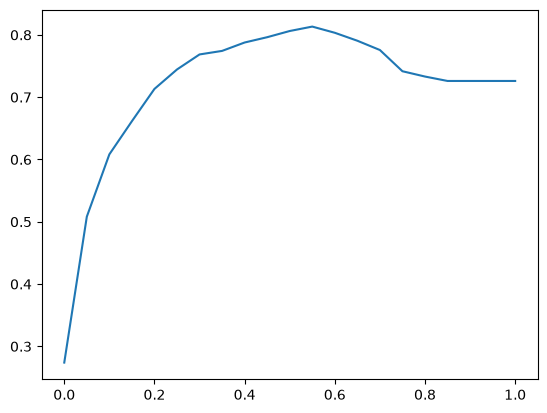

In [81]:
plt.plot(thresholds, scores)

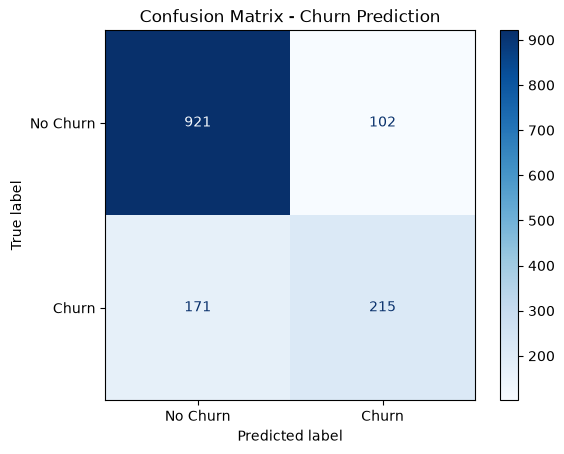

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict_proba(X_val)[:, 1]
y_pred_class = (y_pred >= 0.5).astype(int)

cm = confusion_matrix(y_val, y_pred_class)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Churn Prediction')
plt.show()

In [86]:
from sklearn.metrics import classification_report

print(classification_report(
    y_val,
    y_pred_class,
    target_names=['No Churn', 'Churn'],
    zero_division=0
))

              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1023
       Churn       0.68      0.56      0.61       386

    accuracy                           0.81      1409
   macro avg       0.76      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [87]:
from sklearn.metrics import roc_auc_score

In [88]:
roc_auc_score(y_val, y_pred)

0.853250877486211